This notebook was run on Google Colab (GPU L4) and downloaded from it. 
Shared Colab version: https://colab.research.google.com/drive/1b0u5Fkz4S-z385QBNHCmcFC5UWkdkr7s?usp=sharing

In [1]:
from google.colab import drive
drive.mount("/content/drive")
DRIVE = "/content/drive/MyDrive/DPL_Final"
RAW = f"{DRIVE}/data/raw"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
!git clone https://github.com/iLogicus/image-to-3d-transformer.git /content/project
%cd /content/project
!pip install -r requirements.txt

fatal: destination path '/content/project' already exists and is not an empty directory.
/content/project


In [3]:
!mkdir -p data/raw
!ln -s $DRIVE/data/processed data/processed
!ln -s $DRIVE/outputs outputs

ln: failed to create symbolic link 'data/processed/processed': File exists
ln: failed to create symbolic link 'outputs/outputs': File exists


In [4]:
!nvidia-smi

Tue Nov  3 17:13:21 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   41C    P8             12W /   72W |       0MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [5]:
import sys
sys.path.insert(0, "src")
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
import timm
from PIL import Image
from dataset.shapenet import CLASS_NAMES, image_path, load_cache, load_points, points_path, read_split
from evaluate import load_head
from eval_pix3d import choose_rotation, load_image
from inference import load_model, predict
from metrics import chamfer_fscore
from models.rgb2point import build_head
from utils import load_config

In [6]:
!unzip -q $RAW/rgb2point/ShapeNetRendering.zip "02691156/*" "02958343/*" -d data/raw/ShapeNetRendering
!unzip -q $RAW/r2n2_hf/r2n2_shapenet_dataset_full.zip "*/ShapeNetRendering/03001627/*" -d /content/hf
!mv /content/hf/*/r2n2/ShapeNetRendering/03001627 data/raw/ShapeNetRendering/
!unzip -q $RAW/3dlmnet/ShapeNet_pointclouds.zip "*/02691156/*" "*/02958343/*" "*/03001627/*" -d data/raw
!ls data/raw/*

data/raw/ShapeNet_pointclouds:
02691156  02958343  03001627

data/raw/ShapeNetRendering:
02691156  02958343  03001627


In [7]:
!ln -s $RAW/pix3d data/raw/pix3d
!ln -s $RAW/3dlmnet/pix3d_pointclouds data/raw/pix3d_pointclouds
!ls data/raw/pix3d/img/chair | wc -l

3839


In [8]:
classes = ["car", "airplane", "chair"]
for stage in ["train", "val", "test"]:
    objects = read_split("data/ShapeNet.json", classes, stage)
    for class_id, name in CLASS_NAMES.items():
        count = len([c for c, o in objects if c == class_id])
        print(stage, name, count)

train airplane 2831
train car 5245
train chair 4744
val airplane 404
val car 749
val chair 677
test airplane 810
test car 1501
test chair 1357


In [9]:
author_train = set(open(f"{RAW}/rgb2point/split/shapenet_train.txt").read().split())
test_objects = read_split("data/ShapeNet.json", classes, "test")
for class_id, name in CLASS_NAMES.items():
    ours = [c + "/" + o for c, o in test_objects if c == class_id]
    leak = [x for x in ours if x in author_train]
    print(name, "test objects:", len(ours), "also in author train:", len(leak))

airplane test objects: 810 also in author train: 582
car test objects: 1501 also in author train: 521
chair test objects: 1357 also in author train: 901


In [10]:
official = torch.load(f"{DRIVE}/pretrained/rgb2point_official.pth", map_location="cpu")["model"]
for name in official:
    if not name.startswith("vit."):
        print(name, official[name].shape)

vit = timm.create_model("vit_base_patch16_224", pretrained=True, num_classes=0).state_dict()
same = all(torch.equal(official["vit." + name], vit[name]) for name in vit)
print("Official ViT weights == timm pretrained ViT:", same)

aggregator.weight torch.Size([4096, 768])
aggregator.bias torch.Size([4096])
point_cloud_generator.self_attention.in_proj_weight torch.Size([12288, 4096])
point_cloud_generator.self_attention.in_proj_bias torch.Size([12288])
point_cloud_generator.self_attention.out_proj.weight torch.Size([4096, 4096])
point_cloud_generator.self_attention.out_proj.bias torch.Size([4096])
point_cloud_generator.linear_layers.0.weight torch.Size([2048, 4096])
point_cloud_generator.linear_layers.0.bias torch.Size([2048])
point_cloud_generator.linear_layers.2.weight torch.Size([2048, 2048])
point_cloud_generator.linear_layers.2.bias torch.Size([2048])
point_cloud_generator.linear_layers.4.weight torch.Size([3072, 2048])
point_cloud_generator.linear_layers.4.bias torch.Size([3072])


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Official ViT weights == timm pretrained ViT: True


In [11]:
!python src/cache_features.py --config configs/rgb2point.yaml

[train] already cached
[val] already cached
[test] already cached


In [12]:
!python src/train.py --config configs/rgb2point.yaml

Device: cuda
Training already finished, log:
Epoch 1/50  loss 8.0708  val CD 0.04448  val F 0.1822  lr 1.0e-04  213s
Epoch 2/50  loss 6.6363  val CD 0.04324  val F 0.1932  lr 1.0e-04  213s
Epoch 3/50  loss 6.2515  val CD 0.04262  val F 0.1949  lr 1.0e-04  214s
Epoch 4/50  loss 6.0260  val CD 0.04222  val F 0.1987  lr 1.0e-04  213s
Epoch 5/50  loss 5.8804  val CD 0.04196  val F 0.1995  lr 1.0e-04  213s
Epoch 6/50  loss 5.7593  val CD 0.04152  val F 0.2062  lr 1.0e-04  213s
Epoch 7/50  loss 5.6661  val CD 0.04146  val F 0.2013  lr 1.0e-04  213s
Epoch 8/50  loss 5.5902  val CD 0.04129  val F 0.2106  lr 1.0e-04  212s
Epoch 9/50  loss 5.5207  val CD 0.04114  val F 0.2076  lr 1.0e-04  214s
Epoch 10/50  loss 5.4718  val CD 0.04102  val F 0.2076  lr 1.0e-04  213s
Epoch 11/50  loss 5.4156  val CD 0.04110  val F 0.2101  lr 1.0e-04  212s
Epoch 12/50  loss 5.3734  val CD 0.04076  val F 0.2109  lr 1.0e-04  213s
Epoch 13/50  loss 5.3279  val CD 0.04103  val F 0.2102  lr 1.0e-04  213s
Epoch 14/50  lo

In [13]:
!python src/evaluate.py --config configs/rgb2point.yaml --ckpt outputs/baseline1/base_rgb2point/best.pt --name test_full
!python src/evaluate.py --config configs/rgb2point.yaml --ckpt outputs/baseline1/base_rgb2point/best.pt --exclude $RAW/rgb2point/split/shapenet_train.txt --name test_clean

Checkpoint epoch: 40
class        CD x100  EMD x100    F@0.01
airplane       2.588     4.687    0.5062
car            4.003     3.370    0.1008
chair          5.363     7.903    0.0839
mean           3.985     5.320    0.2303
[test] objects: 3668, images: 3668, skipped (missing files): 0
Params: 175.0M total, 89.2M trainable
Inference: 10.6 ms/image, GPU memory 0.89 GB
Checkpoint epoch: 40
Kept 1664 / 3668 images (dropped objects in /content/drive/MyDrive/DPL_Final/data/raw/rgb2point/split/shapenet_train.txt)
class        CD x100  EMD x100    F@0.01
airplane       2.667     4.489    0.4897
car            4.073     3.449    0.0967
chair          5.506     7.755    0.0778
mean           4.082     5.231    0.2214
[test] objects: 3668, images: 3668, skipped (missing files): 0
Params: 175.0M total, 89.2M trainable
Inference: 10.5 ms/image, GPU memory 0.89 GB


In [14]:
!python src/evaluate.py --config configs/rgb2point.yaml --ckpt $DRIVE/pretrained/rgb2point_official.pth --official --exclude $RAW/rgb2point/split/shapenet_train.txt --name official_test_clean

Loaded official RGB2Point weights
Kept 1664 / 3668 images (dropped objects in /content/drive/MyDrive/DPL_Final/data/raw/rgb2point/split/shapenet_train.txt)
class        CD x100  EMD x100    F@0.01
airplane       2.892     5.276    0.4128
car            4.361     3.830    0.0845
chair          5.591     7.800    0.0737
mean           4.281     5.635    0.1903
[test] objects: 3668, images: 3668, skipped (missing files): 0
Params: 175.0M total, 89.2M trainable
Inference: 10.5 ms/image, GPU memory 0.89 GB


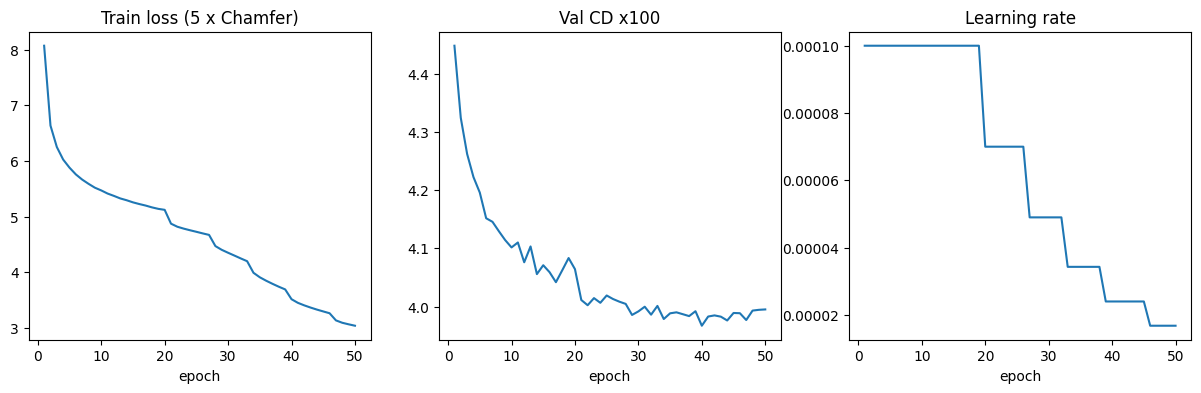

In [15]:
log = [json.loads(line) for line in open("outputs/baseline1/base_rgb2point/log.jsonl")]
epochs = [r["epoch"] for r in log]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(epochs, [r["train_loss"] for r in log])
ax[0].set_title("Train loss (5 x Chamfer)")
ax[1].plot(epochs, [r["val_cd"] * 100 for r in log])
ax[1].set_title("Val CD x100")
ax[2].plot(epochs, [r["lr"] for r in log])
ax[2].set_title("Learning rate")
for a in ax:
    a.set_xlabel("epoch")
plt.show()

In [16]:
paper = {"airplane": [2.73, 5.01], "car": [4.05, 3.59], "chair": [5.38, 7.80]}
runs = {
    "Official weights, clean test": "outputs/baseline1/base_rgb2point/official_test_clean.json",
    "Ours, clean test": "outputs/baseline1/base_rgb2point/test_clean.json",
    "Ours, full test": "outputs/baseline1/base_rgb2point/test_full.json",
}
rows = []
for class_id, name in CLASS_NAMES.items():
    rows.append([name, "Paper", paper[name][0], paper[name][1], None])
    for label, path in runs.items():
        r = json.load(open(path))[class_id]
        rows.append([name, label, r["cd"] * 100, r["emd"] * 100, r["fscore"]])
pd.DataFrame(rows, columns=["class", "model", "CD x100", "EMD x100", "F@0.01"]).round(3)

,class,model,CD x100,EMD x100,F@0.01
0,airplane,Paper,2.730,5.010,NaN
1,airplane,"Official weights, clean test",2.892,5.276,0.413
2,airplane,"Ours, clean test",2.667,4.489,0.490
3,airplane,"Ours, full test",2.588,4.687,0.506
4,car,Paper,4.050,3.590,NaN
5,car,"Official weights, clean test",4.361,3.830,0.085
6,car,"Ours, clean test",4.073,3.449,0.097
7,car,"Ours, full test",4.003,3.370,0.101
8,chair,Paper,5.380,7.800,NaN
9,chair,"Official weights, clean test",5.591,7.800,0.074


In [17]:
!python src/analyze.py --config configs/rgb2point.yaml --ckpt outputs/baseline1/base_rgb2point/best.pt

Checkpoint epoch: 40
[test] objects: 3668, images: 69034, skipped (missing files): 0
100% 270/270 [05:56<00:00,  1.32s/it]
Saved 69034 rows to outputs/baseline1/base_rgb2point/analysis_test.csv


In [18]:
df = pd.read_csv("outputs/baseline1/base_rgb2point/analysis_test.csv")
df["cd"] = df["cd"] * 100
print("Elevation range:", df["elevation"].min(), "-", df["elevation"].max())
df["azimuth_bin"] = (df["azimuth"] // 45) * 45
print(df.pivot_table(index="class", columns="azimuth_bin", values="cd").round(2))

Elevation range: 25.0000745815 - 29.9999099786
azimuth_bin  0.0    45.0   90.0   135.0  180.0  225.0  270.0  315.0
class                                                              
airplane      2.61   2.55   2.60   2.62   2.59   2.51   2.51   2.61
car           4.06   3.96   3.95   4.02   4.02   3.97   3.96   4.02
chair         5.35   5.24   5.31   5.46   5.55   5.31   5.35   5.35


In [19]:
per_object = df.groupby(["class", "object"])["cd"].mean()
print("Std of CD between objects:", per_object.groupby("class").std().round(2).to_dict())
print("Std of CD between views of one object:", df.groupby(["class", "object"])["cd"].std().groupby("class").mean().round(2).to_dict())

Std of CD between objects: {'airplane': 1.01, 'car': 0.58, 'chair': 1.47}
Std of CD between views of one object: {'airplane': 0.24, 'car': 0.21, 'chair': 0.61}


In [20]:
cfg = load_config("configs/rgb2point.yaml")
test = load_cache(cfg["data"], "test", "cuda")
head = build_head(cfg["model"], 768, 1024).cuda()
load_head(head, "outputs/baseline1/base_rgb2point/best.pt", False)
head.eval()
with torch.no_grad():
    pred = head(test["features"].cuda().float())
gt = test["points"]
class_of = np.array(test["class_ids"])

for class_id, name in CLASS_NAMES.items():
    idx = np.where(class_of == class_id)[0]
    other = np.roll(idx, 1)
    cd_pred, _ = chamfer_fscore(pred[idx], pred[other])
    cd_gt, _ = chamfer_fscore(gt[idx], gt[other])
    print(name, "CD between 2 different objects: predictions", round(cd_pred.mean().item() * 100, 2), "| ground truth", round(cd_gt.mean().item() * 100, 2))

Checkpoint epoch: 40
airplane CD between 2 different objects: predictions 3.06 | ground truth 5.1
car CD between 2 different objects: predictions 4.26 | ground truth 5.47
chair CD between 2 different objects: predictions 7.67 | ground truth 11.21


In [21]:
for class_id, name in CLASS_NAMES.items():
    cds, fs = [], []
    for obj in [o for o in test["objects"] if o[0] == class_id][:300]:
        p1024 = np.load(points_path(cfg["data"], *obj))
        p2048 = np.load(points_path(cfg["data"], *obj).replace("1024", "2048"))
        other_sample = p2048[np.random.RandomState(0).permutation(2048)[:1024]]
        cd, f = chamfer_fscore(torch.tensor(other_sample - p1024.mean(0))[None], torch.tensor(p1024 - p1024.mean(0))[None])
        cds.append(cd.item())
        fs.append(f.item())
    print(name, "best possible with 1024 points (another sample of the same surface): CD", round(np.mean(cds) * 100, 2), "F@0.01", round(np.mean(fs), 3))

airplane best possible with 1024 points (another sample of the same surface): CD 1.43 F@0.01 0.768
car best possible with 1024 points (another sample of the same surface): CD 4.49 F@0.01 0.167
chair best possible with 1024 points (another sample of the same surface): CD 2.56 F@0.01 0.35


In [22]:
for class_id, name in CLASS_NAMES.items():
    points = gt[class_of == class_id]
    diagonal = (points.max(1).values - points.min(1).values).norm(dim=1).cpu()
    print(name, "GT bounding box diagonal: median", round(diagonal.median().item(), 3), "| objects with diagonal < 0.8:", (diagonal < 0.8).sum().item(), "of", len(diagonal))

airplane GT bounding box diagonal: median 0.996 | objects with diagonal < 0.8: 12 of 810
car GT bounding box diagonal: median 0.994 | objects with diagonal < 0.8: 0 of 1501
chair GT bounding box diagonal: median 0.999 | objects with diagonal < 0.8: 4 of 1357


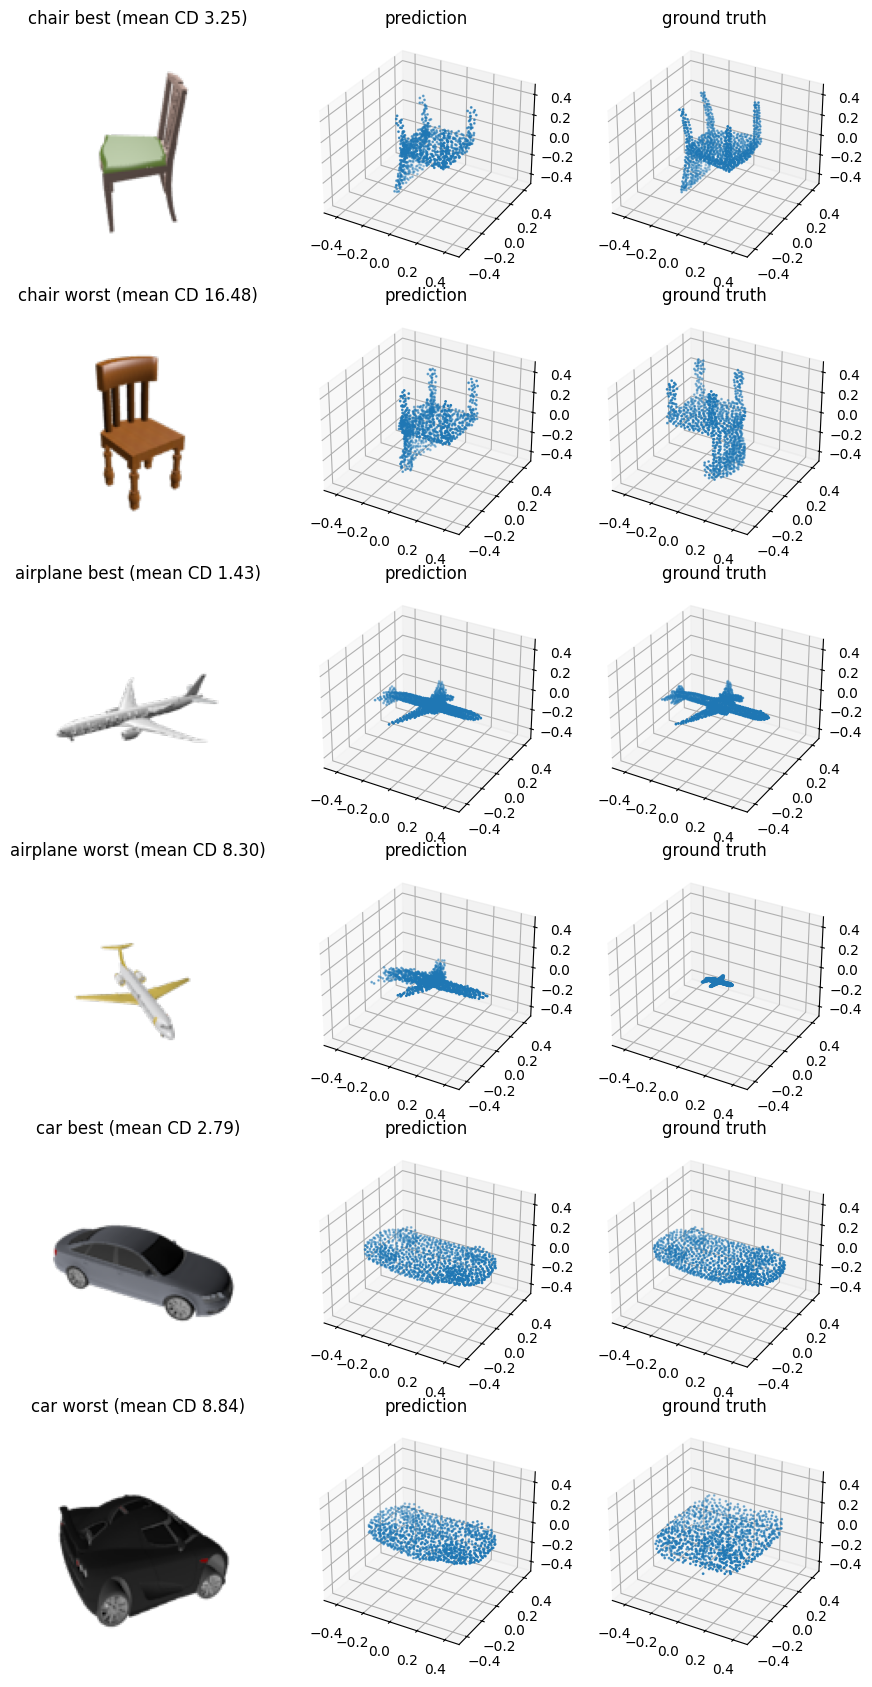

In [23]:
examples = []
for name in ["chair", "airplane", "car"]:
    objects = per_object[name].sort_values()
    examples.append((name, objects.index[0], "best"))
    examples.append((name, objects.index[-1], "worst"))

position = {obj: i for i, (c, obj) in enumerate(test["objects"])}
fig = plt.figure(figsize=(9, 2.8 * len(examples)))
for row, (name, obj, label) in enumerate(examples):
    i = position[obj]
    ax = fig.add_subplot(len(examples), 3, 3 * row + 1)
    ax.imshow(Image.open(image_path(cfg["data"], test["objects"][i][0], obj, 0)))
    ax.set_title(f"{name} {label} (mean CD {per_object[name][obj]:.2f})")
    ax.axis("off")
    for col, (title, points) in enumerate([("prediction", pred[i]), ("ground truth", gt[i])]):
        p = points.cpu().numpy()
        ax = fig.add_subplot(len(examples), 3, 3 * row + 2 + col, projection="3d")
        ax.scatter(p[:, 2], p[:, 1], p[:, 0], s=1)
        ax.set_xlim(-0.5, 0.5)
        ax.set_ylim(-0.5, 0.5)
        ax.set_zlim(-0.5, 0.5)
        ax.set_title(title)
plt.tight_layout()
plt.show()

In [24]:
!python src/train.py --config configs/v0_no_attention.yaml

Device: cuda
Training already finished, log:
Epoch 1/50  loss 7.6649  val CD 0.04436  val F 0.1791  lr 1.0e-04  101s
Epoch 2/50  loss 6.4985  val CD 0.04365  val F 0.1874  lr 1.0e-04  100s
Epoch 3/50  loss 6.0905  val CD 0.04285  val F 0.1919  lr 1.0e-04  100s
Epoch 4/50  loss 5.8337  val CD 0.04247  val F 0.1986  lr 1.0e-04  100s
Epoch 5/50  loss 5.6494  val CD 0.04223  val F 0.1986  lr 1.0e-04  101s
Epoch 6/50  loss 5.4998  val CD 0.04207  val F 0.1983  lr 1.0e-04  101s
Epoch 7/50  loss 5.3821  val CD 0.04178  val F 0.2015  lr 1.0e-04  100s
Epoch 8/50  loss 5.2857  val CD 0.04170  val F 0.2034  lr 1.0e-04  101s
Epoch 9/50  loss 5.2033  val CD 0.04171  val F 0.2017  lr 1.0e-04  100s
Epoch 10/50  loss 5.1353  val CD 0.04155  val F 0.2021  lr 1.0e-04  100s
Epoch 11/50  loss 5.0644  val CD 0.04139  val F 0.2083  lr 1.0e-04  101s
Epoch 12/50  loss 5.0131  val CD 0.04134  val F 0.2057  lr 1.0e-04  101s
Epoch 13/50  loss 4.9586  val CD 0.04146  val F 0.2052  lr 1.0e-04  100s
Epoch 14/50  lo

In [25]:
!python src/evaluate.py --config configs/v0_no_attention.yaml --ckpt outputs/baseline1/v0_no_attention/best.pt --name test_full
!python src/evaluate.py --config configs/v0_no_attention.yaml --ckpt outputs/baseline1/v0_no_attention/best.pt --exclude $RAW/rgb2point/split/shapenet_train.txt --name test_clean

Checkpoint epoch: 38
class        CD x100  EMD x100    F@0.01
airplane       2.608     4.052    0.5070
car            4.028     3.375    0.1001
chair          5.412     6.355    0.0871
mean           4.016     4.594    0.2314
[test] objects: 3668, images: 3668, skipped (missing files): 0
Params: 107.8M total, 22.0M trainable
Inference: 8.8 ms/image, GPU memory 0.49 GB
Checkpoint epoch: 38
Kept 1664 / 3668 images (dropped objects in /content/drive/MyDrive/DPL_Final/data/raw/rgb2point/split/shapenet_train.txt)
class        CD x100  EMD x100    F@0.01
airplane       2.679     3.948    0.4921
car            4.096     3.447    0.0971
chair          5.612     6.333    0.0797
mean           4.129     4.576    0.2230
[test] objects: 3668, images: 3668, skipped (missing files): 0
Params: 107.8M total, 22.0M trainable
Inference: 8.6 ms/image, GPU memory 0.49 GB


In [26]:
!python src/cache_features.py --config configs/v1_query.yaml

[train] already cached
[val] already cached
[test] already cached


In [27]:
!python src/train.py --config configs/v1_query.yaml

Device: cuda
Training already finished, log:
Epoch 1/50  loss 11.2363  val CD 0.04494  val F 0.1689  lr 1.0e-04  225s
Epoch 2/50  loss 6.6962  val CD 0.04343  val F 0.1771  lr 1.0e-04  213s
Epoch 3/50  loss 6.1834  val CD 0.04232  val F 0.1797  lr 1.0e-04  212s
Epoch 4/50  loss 5.8368  val CD 0.04142  val F 0.1954  lr 1.0e-04  213s
Epoch 5/50  loss 5.5780  val CD 0.04068  val F 0.1990  lr 1.0e-04  211s
Epoch 6/50  loss 5.3813  val CD 0.04059  val F 0.1978  lr 1.0e-04  213s
Epoch 7/50  loss 5.2059  val CD 0.03988  val F 0.2103  lr 1.0e-04  212s
Epoch 8/50  loss 5.0676  val CD 0.03960  val F 0.2147  lr 1.0e-04  213s
Epoch 9/50  loss 4.9355  val CD 0.03961  val F 0.2104  lr 1.0e-04  212s
Epoch 10/50  loss 4.8277  val CD 0.03913  val F 0.2135  lr 1.0e-04  212s
Epoch 11/50  loss 4.7273  val CD 0.03899  val F 0.2204  lr 1.0e-04  212s
Epoch 12/50  loss 4.6386  val CD 0.03904  val F 0.2206  lr 1.0e-04  212s
Epoch 13/50  loss 4.5460  val CD 0.03880  val F 0.2237  lr 1.0e-04  212s
Epoch 14/50  l

In [28]:
!python src/evaluate.py --config configs/v1_query.yaml --ckpt outputs/baseline1/v1_query/best.pt --name test_full
!python src/evaluate.py --config configs/v1_query.yaml --ckpt outputs/baseline1/v1_query/best.pt --exclude $RAW/rgb2point/split/shapenet_train.txt --name test_clean

Checkpoint epoch: 38
class        CD x100  EMD x100    F@0.01
airplane       2.495     4.225    0.5262
car            3.856     3.204    0.1102
chair          4.906     5.926    0.0995
mean           3.752     4.452    0.2453
[test] objects: 3668, images: 3668, skipped (missing files): 0
Params: 90.3M total, 4.5M trainable
Inference: 13.2 ms/image, GPU memory 0.38 GB
Checkpoint epoch: 38
Kept 1664 / 3668 images (dropped objects in /content/drive/MyDrive/DPL_Final/data/raw/rgb2point/split/shapenet_train.txt)
class        CD x100  EMD x100    F@0.01
airplane       2.620     4.124    0.5070
car            3.932     3.293    0.1056
chair          5.071     5.917    0.0919
mean           3.874     4.445    0.2349
[test] objects: 3668, images: 3668, skipped (missing files): 0
Params: 90.3M total, 4.5M trainable
Inference: 13.3 ms/image, GPU memory 0.38 GB


In [29]:
!python src/analyze.py --config configs/v1_query.yaml --ckpt outputs/baseline1/v1_query/best.pt

Checkpoint epoch: 38
[test] objects: 3668, images: 69034, skipped (missing files): 0
100% 270/270 [06:03<00:00,  1.35s/it]
Saved 69034 rows to outputs/baseline1/v1_query/analysis_test.csv


airplane | objects improved: 74.2 % | median change: -2.5 % | hardest 10% for baseline: CD 4.83 -> 4.64
car | objects improved: 82.3 % | median change: -2.9 % | hardest 10% for baseline: CD 5.26 -> 4.92
chair | objects improved: 85.3 % | median change: -7.1 % | hardest 10% for baseline: CD 8.54 -> 7.56


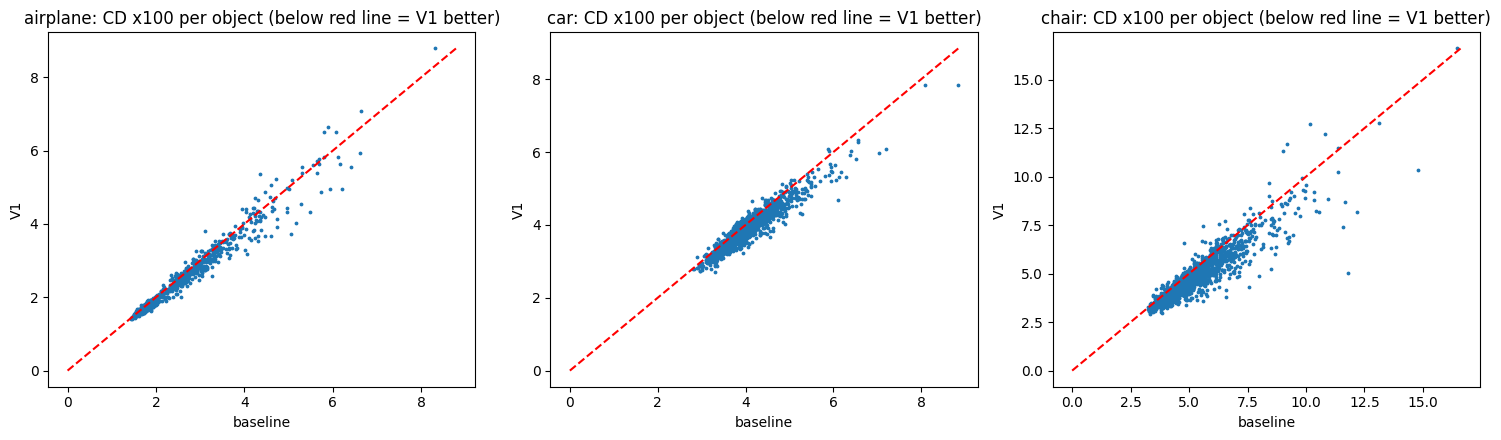

In [30]:
base = pd.read_csv("outputs/baseline1/base_rgb2point/analysis_test.csv").groupby(["class", "object"])["cd"].mean() * 100
v1 = pd.read_csv("outputs/baseline1/v1_query/analysis_test.csv").groupby(["class", "object"])["cd"].mean() * 100
compare = pd.DataFrame({"baseline": base, "v1": v1})
compare["change %"] = (compare["v1"] / compare["baseline"] - 1) * 100

for name in ["airplane", "car", "chair"]:
    c = compare.loc[name]
    hard = c[c["baseline"] > c["baseline"].quantile(0.9)]
    print(name, "| objects improved:", round((c["v1"] < c["baseline"]).mean() * 100, 1), "%",
          "| median change:", round(c["change %"].median(), 1), "%",
          "| hardest 10% for baseline: CD", round(hard["baseline"].mean(), 2), "->", round(hard["v1"].mean(), 2))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for a, name in zip(ax, ["airplane", "car", "chair"]):
    c = compare.loc[name]
    a.scatter(c["baseline"], c["v1"], s=3)
    top = max(c["baseline"].max(), c["v1"].max())
    a.plot([0, top], [0, top], "r--")
    a.set_title(f"{name}: CD x100 per object (below red line = V1 better)")
    a.set_xlabel("baseline")
    a.set_ylabel("V1")
plt.tight_layout()
plt.show()

In [31]:
cfg_v1 = load_config("configs/v1_query.yaml")
test_v1 = load_cache(cfg_v1["data"], "test", "cuda")
head_v1 = build_head(cfg_v1["model"], 768, 1024).cuda()
load_head(head_v1, "outputs/baseline1/v1_query/best.pt", False)
head_v1.eval()
with torch.no_grad():
    pred_v1 = torch.cat([head_v1(test_v1["features"][i:i + 256].cuda().float()) for i in range(0, len(test_v1["features"]), 256)])
gt = test_v1["points"]
class_of = np.array(test_v1["class_ids"])

for class_id, name in CLASS_NAMES.items():
    idx = np.where(class_of == class_id)[0]
    other = np.roll(idx, 1)
    cd_pred, _ = chamfer_fscore(pred_v1[idx], pred_v1[other])
    cd_gt, _ = chamfer_fscore(gt[idx], gt[other])
    print(name, "CD between 2 different objects: V1 predictions", round(cd_pred.mean().item() * 100, 2), "| ground truth", round(cd_gt.mean().item() * 100, 2))

Checkpoint epoch: 38
airplane CD between 2 different objects: V1 predictions 3.41 | ground truth 5.1
car CD between 2 different objects: V1 predictions 4.5 | ground truth 5.47
chair CD between 2 different objects: V1 predictions 9.31 | ground truth 11.21


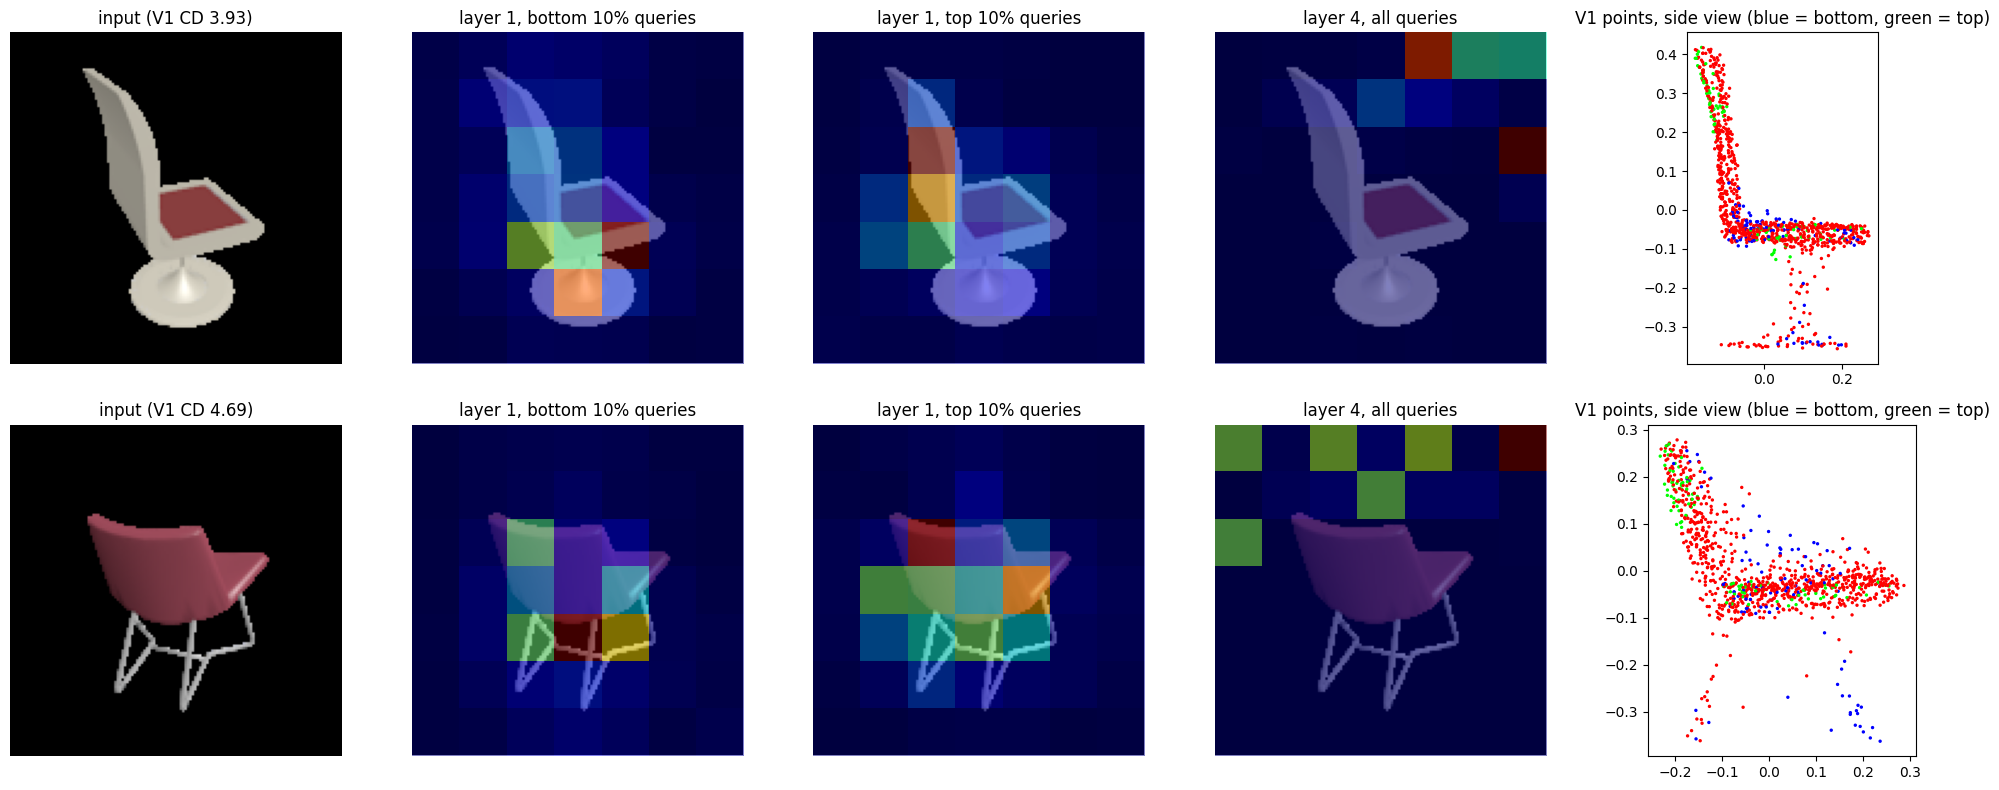

In [32]:
chairs = compare.loc["chair"].sort_values("v1")
chosen = [chairs.index[len(chairs) // 4], chairs.index[len(chairs) // 2]]
position = {obj: i for i, (c, obj) in enumerate(test_v1["objects"])}

fig, ax = plt.subplots(len(chosen), 5, figsize=(20, 4 * len(chosen)))
for row, obj in enumerate(chosen):
    i = position[obj]
    with torch.no_grad():
        points, maps = head_v1.attention_maps(test_v1["features"][i:i + 1].cuda().float())
    points = points[0].cpu().numpy()
    height = -points[:, 0].reshape(256, 4).mean(1)
    bottom = height < np.quantile(height, 0.1)
    top = height > np.quantile(height, 0.9)
    image = Image.open(image_path(cfg_v1["data"], "03001627", obj, 0)).convert("RGB")
    panels = [("layer 1, bottom 10% queries", maps[0][0, bottom]),
              ("layer 1, top 10% queries", maps[0][0, top]),
              ("layer 4, all queries", maps[-1][0])]
    ax[row, 0].imshow(image)
    ax[row, 0].set_title(f"input (V1 CD {compare.loc[('chair', obj), 'v1']:.2f})")
    for col, (title, weights) in enumerate(panels):
        attention = weights[:, 1:].mean(0).reshape(7, 7).cpu().numpy()
        ax[row, 1 + col].imshow(image)
        ax[row, 1 + col].imshow(attention, cmap="jet", alpha=0.5, extent=(0, image.width, image.height, 0))
        ax[row, 1 + col].set_title(title)
    for a in ax[row, :4]:
        a.axis("off")
    colors = np.repeat(np.where(bottom, 0, np.where(top, 2, 1)), 4)
    ax[row, 4].scatter(points[:, 2], -points[:, 0], c=colors, cmap="brg", s=2)
    ax[row, 4].set_aspect("equal")
    ax[row, 4].set_title("V1 points, side view (blue = bottom, green = top)")
plt.tight_layout()
plt.show()

In [33]:
on_object = np.zeros(4)
object_area = 0
samples = range(0, len(test_v1["objects"]), 7)
for i in samples:
    class_id, obj = test_v1["objects"][i]
    alpha = np.array(Image.open(image_path(cfg_v1["data"], class_id, obj, 0)).resize((224, 224)))[:, :, 3] > 0
    cell_is_object = alpha.reshape(7, 32, 7, 32).mean(axis=(1, 3)).flatten()
    object_area += cell_is_object.mean()
    with torch.no_grad():
        _, maps = head_v1.attention_maps(test_v1["features"][i:i + 1].cuda().float())
    for layer in range(4):
        weights = maps[layer][0, :, 1:].cpu().numpy()
        on_object[layer] += (weights * cell_is_object).sum(1).mean() / weights.sum(1).mean()
print("Share of image area covered by the object:", round(object_area / len(samples), 3))
for layer in range(4):
    print(f"Decoder layer {layer + 1}: share of patch attention on object cells {on_object[layer] / len(samples):.3f}")

Share of image area covered by the object: 0.151
Decoder layer 1: share of patch attention on object cells 0.372
Decoder layer 2: share of patch attention on object cells 0.121
Decoder layer 3: share of patch attention on object cells 0.005
Decoder layer 4: share of patch attention on object cells 0.003


In [34]:
!python src/cache_features.py --config configs/v2_dinov2.yaml


model.safetensors: downloading bytes:  67% 233M/346M [00:01<00:00, 238MB/s, 17.9MB/s  ]
model.safetensors: downloading bytes:  85% 294M/346M [00:01<00:00, 303MB/s, 21.8MB/s  ]
model.safetensors: downloading bytes: 100% 331M/331M [00:02<00:00, 130MB/s, 30.4MB/s  ]
model.safetensors: reconstructing file: 100% 346M/346M [00:02<00:00, 136MB/s, 32.5MB/s  ]
[train] already cached
[val] already cached
[test] already cached


In [35]:
!python src/train.py --config configs/v2_dinov2.yaml

Device: cuda
Training already finished, log:
Epoch 1/50  loss 8.9226  val CD 0.04157  val F 0.1915  lr 1.0e-04  239s
Epoch 2/50  loss 5.5421  val CD 0.03975  val F 0.1996  lr 1.0e-04  219s
Epoch 3/50  loss 5.1110  val CD 0.03826  val F 0.2136  lr 1.0e-04  220s
Epoch 4/50  loss 4.8430  val CD 0.03773  val F 0.2262  lr 1.0e-04  219s
Epoch 5/50  loss 4.6475  val CD 0.03762  val F 0.2226  lr 1.0e-04  223s
Epoch 6/50  loss 4.4959  val CD 0.03710  val F 0.2252  lr 1.0e-04  221s
Epoch 7/50  loss 4.3710  val CD 0.03685  val F 0.2334  lr 1.0e-04  221s
Epoch 8/50  loss 4.2615  val CD 0.03636  val F 0.2397  lr 1.0e-04  223s
Epoch 9/50  loss 4.1699  val CD 0.03639  val F 0.2356  lr 1.0e-04  223s
Epoch 10/50  loss 4.0947  val CD 0.03604  val F 0.2448  lr 1.0e-04  223s
Epoch 11/50  loss 4.0199  val CD 0.03586  val F 0.2425  lr 1.0e-04  223s
Epoch 12/50  loss 3.9565  val CD 0.03570  val F 0.2487  lr 1.0e-04  222s
Epoch 13/50  loss 3.8969  val CD 0.03578  val F 0.2496  lr 1.0e-04  221s
Epoch 14/50  lo

In [36]:
!python src/evaluate.py --config configs/v2_dinov2.yaml --ckpt outputs/baseline1/v2_dinov2/best.pt --name test_full
!python src/evaluate.py --config configs/v2_dinov2.yaml --ckpt outputs/baseline1/v2_dinov2/best.pt --exclude $RAW/rgb2point/split/shapenet_train.txt --name test_clean

Checkpoint epoch: 50
class        CD x100  EMD x100    F@0.01
airplane       2.282     3.391    0.5809
car            3.694     3.062    0.1218
chair          4.424     5.477    0.1191
mean           3.467     3.977    0.2739
[test] objects: 3668, images: 3668, skipped (missing files): 0
Params: 90.2M total, 4.5M trainable
Inference: 13.6 ms/image, GPU memory 0.38 GB
Checkpoint epoch: 50
Kept 1664 / 3668 images (dropped objects in /content/drive/MyDrive/DPL_Final/data/raw/rgb2point/split/shapenet_train.txt)
class        CD x100  EMD x100    F@0.01
airplane       2.404     3.421    0.5568
car            3.756     3.145    0.1173
chair          4.586     5.492    0.1097
mean           3.582     4.019    0.2613
[test] objects: 3668, images: 3668, skipped (missing files): 0
Params: 90.2M total, 4.5M trainable
Inference: 13.8 ms/image, GPU memory 0.38 GB


In [37]:
!python src/analyze.py --config configs/v2_dinov2.yaml --ckpt outputs/baseline1/v2_dinov2/best.pt

Checkpoint epoch: 50
[test] objects: 3668, images: 69034, skipped (missing files): 0
100% 270/270 [06:41<00:00,  1.49s/it]
Saved 69034 rows to outputs/baseline1/v2_dinov2/analysis_test.csv


airplane | objects improved over V1: 92.7 % | median change: -7.6 % | hardest 10% for baseline: CD 4.83 -> 4.64 -> 4.28
car | objects improved over V1: 91.8 % | median change: -3.8 % | hardest 10% for baseline: CD 5.26 -> 4.92 -> 4.68
chair | objects improved over V1: 92.1 % | median change: -10.2 % | hardest 10% for baseline: CD 8.54 -> 7.56 -> 6.77


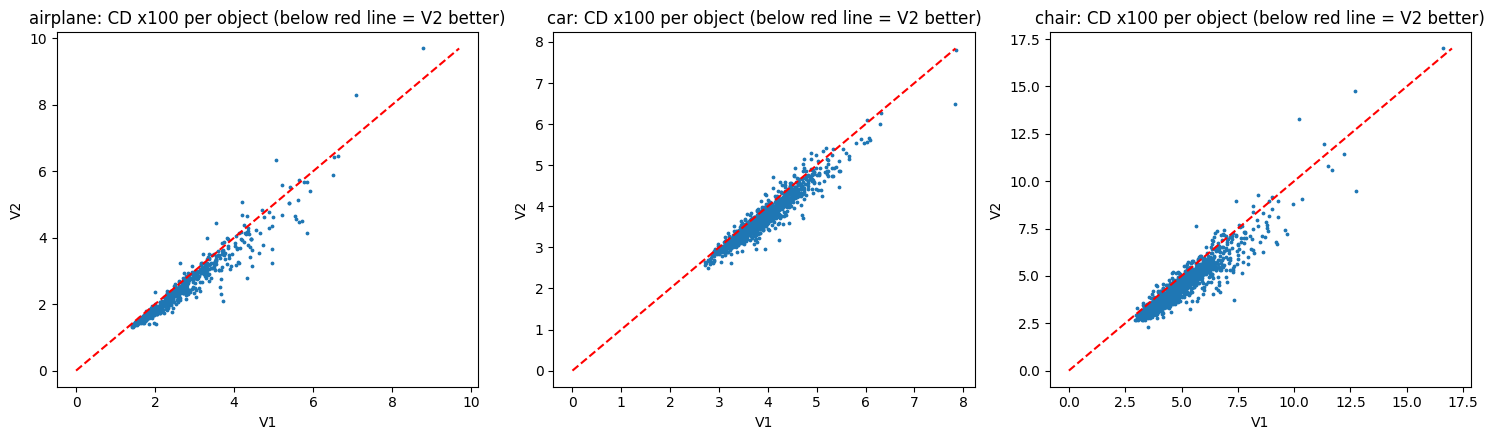

In [38]:
compare["v2"] = pd.read_csv("outputs/baseline1/v2_dinov2/analysis_test.csv").groupby(["class", "object"])["cd"].mean() * 100
compare["v2 vs v1 %"] = (compare["v2"] / compare["v1"] - 1) * 100

for name in ["airplane", "car", "chair"]:
    c = compare.loc[name]
    hard = c[c["baseline"] > c["baseline"].quantile(0.9)]
    print(name, "| objects improved over V1:", round((c["v2"] < c["v1"]).mean() * 100, 1), "%",
          "| median change:", round(c["v2 vs v1 %"].median(), 1), "%",
          "| hardest 10% for baseline: CD", round(hard["baseline"].mean(), 2), "->", round(hard["v1"].mean(), 2), "->", round(hard["v2"].mean(), 2))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for a, name in zip(ax, ["airplane", "car", "chair"]):
    c = compare.loc[name]
    a.scatter(c["v1"], c["v2"], s=3)
    top = max(c["v1"].max(), c["v2"].max())
    a.plot([0, top], [0, top], "r--")
    a.set_title(f"{name}: CD x100 per object (below red line = V2 better)")
    a.set_xlabel("V1")
    a.set_ylabel("V2")
plt.tight_layout()
plt.show()

In [39]:
cfg_v2 = load_config("configs/v2_dinov2.yaml")
test_v2 = load_cache(cfg_v2["data"], "test", "cuda")
head_v2 = build_head(cfg_v2["model"], 768, 1024).cuda()
load_head(head_v2, "outputs/baseline1/v2_dinov2/best.pt", False)
head_v2.eval()
with torch.no_grad():
    pred_v2 = torch.cat([head_v2(test_v2["features"][i:i + 256].cuda().float()) for i in range(0, len(test_v2["features"]), 256)])

for class_id, name in CLASS_NAMES.items():
    idx = np.where(class_of == class_id)[0]
    other = np.roll(idx, 1)
    cd_pred, _ = chamfer_fscore(pred_v2[idx], pred_v2[other])
    cd_gt, _ = chamfer_fscore(gt[idx], gt[other])
    print(name, "CD between 2 different objects: V2 predictions", round(cd_pred.mean().item() * 100, 2), "| ground truth", round(cd_gt.mean().item() * 100, 2))

Checkpoint epoch: 50
airplane CD between 2 different objects: V2 predictions 3.92 | ground truth 5.1
car CD between 2 different objects: V2 predictions 4.76 | ground truth 5.47
chair CD between 2 different objects: V2 predictions 9.92 | ground truth 11.21


In [40]:
on_object = np.zeros(4)
for i in samples:
    class_id, obj = test_v2["objects"][i]
    alpha = np.array(Image.open(image_path(cfg_v2["data"], class_id, obj, 0)).resize((224, 224)))[:, :, 3] > 0
    cell_is_object = alpha.reshape(7, 32, 7, 32).mean(axis=(1, 3)).flatten()
    with torch.no_grad():
        _, maps = head_v2.attention_maps(test_v2["features"][i:i + 1].cuda().float())
    for layer in range(4):
        weights = maps[layer][0, :, 1:].cpu().numpy()
        on_object[layer] += (weights * cell_is_object).sum(1).mean() / weights.sum(1).mean()
for layer in range(4):
    print(f"V2 decoder layer {layer + 1}: share of patch attention on object cells {on_object[layer] / len(samples):.3f}")

V2 decoder layer 1: share of patch attention on object cells 0.365
V2 decoder layer 2: share of patch attention on object cells 0.147
V2 decoder layer 3: share of patch attention on object cells 0.106
V2 decoder layer 4: share of patch attention on object cells 0.235


In [41]:
!python src/train_finetune.py --config configs/v3_finetune.yaml

Training already finished, log:
Epoch 1/8  loss 3.3786  val CD 0.03507  val F 0.2603  lr 2.9e-05  939s
Epoch 2/8  loss 3.1282  val CD 0.03448  val F 0.2698  lr 2.6e-05  938s
Epoch 3/8  loss 3.0053  val CD 0.03439  val F 0.2693  lr 2.1e-05  938s
Epoch 4/8  loss 2.9150  val CD 0.03422  val F 0.2713  lr 1.5e-05  938s
Epoch 5/8  loss 2.8454  val CD 0.03419  val F 0.2721  lr 9.3e-06  938s
Epoch 6/8  loss 2.7927  val CD 0.03408  val F 0.2733  lr 4.4e-06  938s
Epoch 7/8  loss 2.7564  val CD 0.03396  val F 0.2759  lr 1.1e-06  938s
Epoch 8/8  loss 2.7374  val CD 0.03398  val F 0.2749  lr 0.0e+00  938s


In [42]:
!python src/cache_features.py --config configs/v3_finetune.yaml --ckpt outputs/baseline1/v3_finetune/best.pt --stages val test

Loaded fine-tuned ViT
[val] already cached
[test] already cached


In [43]:
!python src/evaluate.py --config configs/v3_finetune.yaml --ckpt outputs/baseline1/v3_finetune/best.pt --name test_full
!python src/evaluate.py --config configs/v3_finetune.yaml --ckpt outputs/baseline1/v3_finetune/best.pt --exclude $RAW/rgb2point/split/shapenet_train.txt --name test_clean

Checkpoint epoch: 7
Loaded fine-tuned ViT
class        CD x100  EMD x100    F@0.01
airplane       2.262     3.324    0.5750
car            3.651     3.063    0.1265
chair          4.360     5.266    0.1186
mean           3.424     3.884    0.2734
[test] objects: 3668, images: 3668, skipped (missing files): 0
Params: 90.2M total, 32.9M trainable
Inference: 14.8 ms/image, GPU memory 0.44 GB
Checkpoint epoch: 7
Loaded fine-tuned ViT
Kept 1664 / 3668 images (dropped objects in /content/drive/MyDrive/DPL_Final/data/raw/rgb2point/split/shapenet_train.txt)
class        CD x100  EMD x100    F@0.01
airplane       2.393     3.365    0.5489
car            3.716     3.150    0.1210
chair          4.539     5.331    0.1096
mean           3.550     3.949    0.2598
[test] objects: 3668, images: 3668, skipped (missing files): 0
Params: 90.2M total, 32.9M trainable
Inference: 14.6 ms/image, GPU memory 0.44 GB


In [44]:
!python src/eval_pix3d.py --config configs/rgb2point.yaml --ckpt outputs/baseline1/base_rgb2point/best.pt
!python src/eval_pix3d.py --config configs/v1_query.yaml --ckpt outputs/baseline1/v1_query/best.pt
!python src/eval_pix3d.py --config configs/v2_dinov2.yaml --ckpt outputs/baseline1/v2_dinov2/best.pt
!python src/eval_pix3d.py --config configs/v3_finetune.yaml --ckpt outputs/baseline1/v3_finetune/best.pt

Pix3D chair images: 2777
Chosen rotation (Pix3D -> ShapeNet axes):
 [[ 0. -1.  0.]
 [-1.  0.  0.]
 [ 0.  0. -1.]] 
mean CD to nearest ShapeNet chair: 7.833
Checkpoint epoch: 40
100% 44/44 [10:45<00:00, 14.66s/it]
Pix3D chair: CD x100 6.545  F@0.01 0.0804
Pix3D chair images: 2777
Chosen rotation (Pix3D -> ShapeNet axes):
 [[ 0. -1.  0.]
 [-1.  0.  0.]
 [ 0.  0. -1.]] 
mean CD to nearest ShapeNet chair: 7.833
Checkpoint epoch: 38
100% 44/44 [02:04<00:00,  2.84s/it]
Pix3D chair: CD x100 6.272  F@0.01 0.0918
Pix3D chair images: 2777
Chosen rotation (Pix3D -> ShapeNet axes):
 [[ 0. -1.  0.]
 [-1.  0.  0.]
 [ 0.  0. -1.]] 
mean CD to nearest ShapeNet chair: 7.833
Checkpoint epoch: 50
100% 44/44 [02:05<00:00,  2.85s/it]
Pix3D chair: CD x100 5.761  F@0.01 0.1065
Pix3D chair images: 2777
Chosen rotation (Pix3D -> ShapeNet axes):
 [[ 0. -1.  0.]
 [-1.  0.  0.]
 [ 0.  0. -1.]] 
mean CD to nearest ShapeNet chair: 7.833
Checkpoint epoch: 7
Loaded fine-tuned ViT
100% 44/44 [02:05<00:00,  2.85s/it]
P

Chosen rotation (Pix3D -> ShapeNet axes):
 [[ 0. -1.  0.]
 [-1.  0.  0.]
 [ 0.  0. -1.]] 
mean CD to nearest ShapeNet chair: 7.833


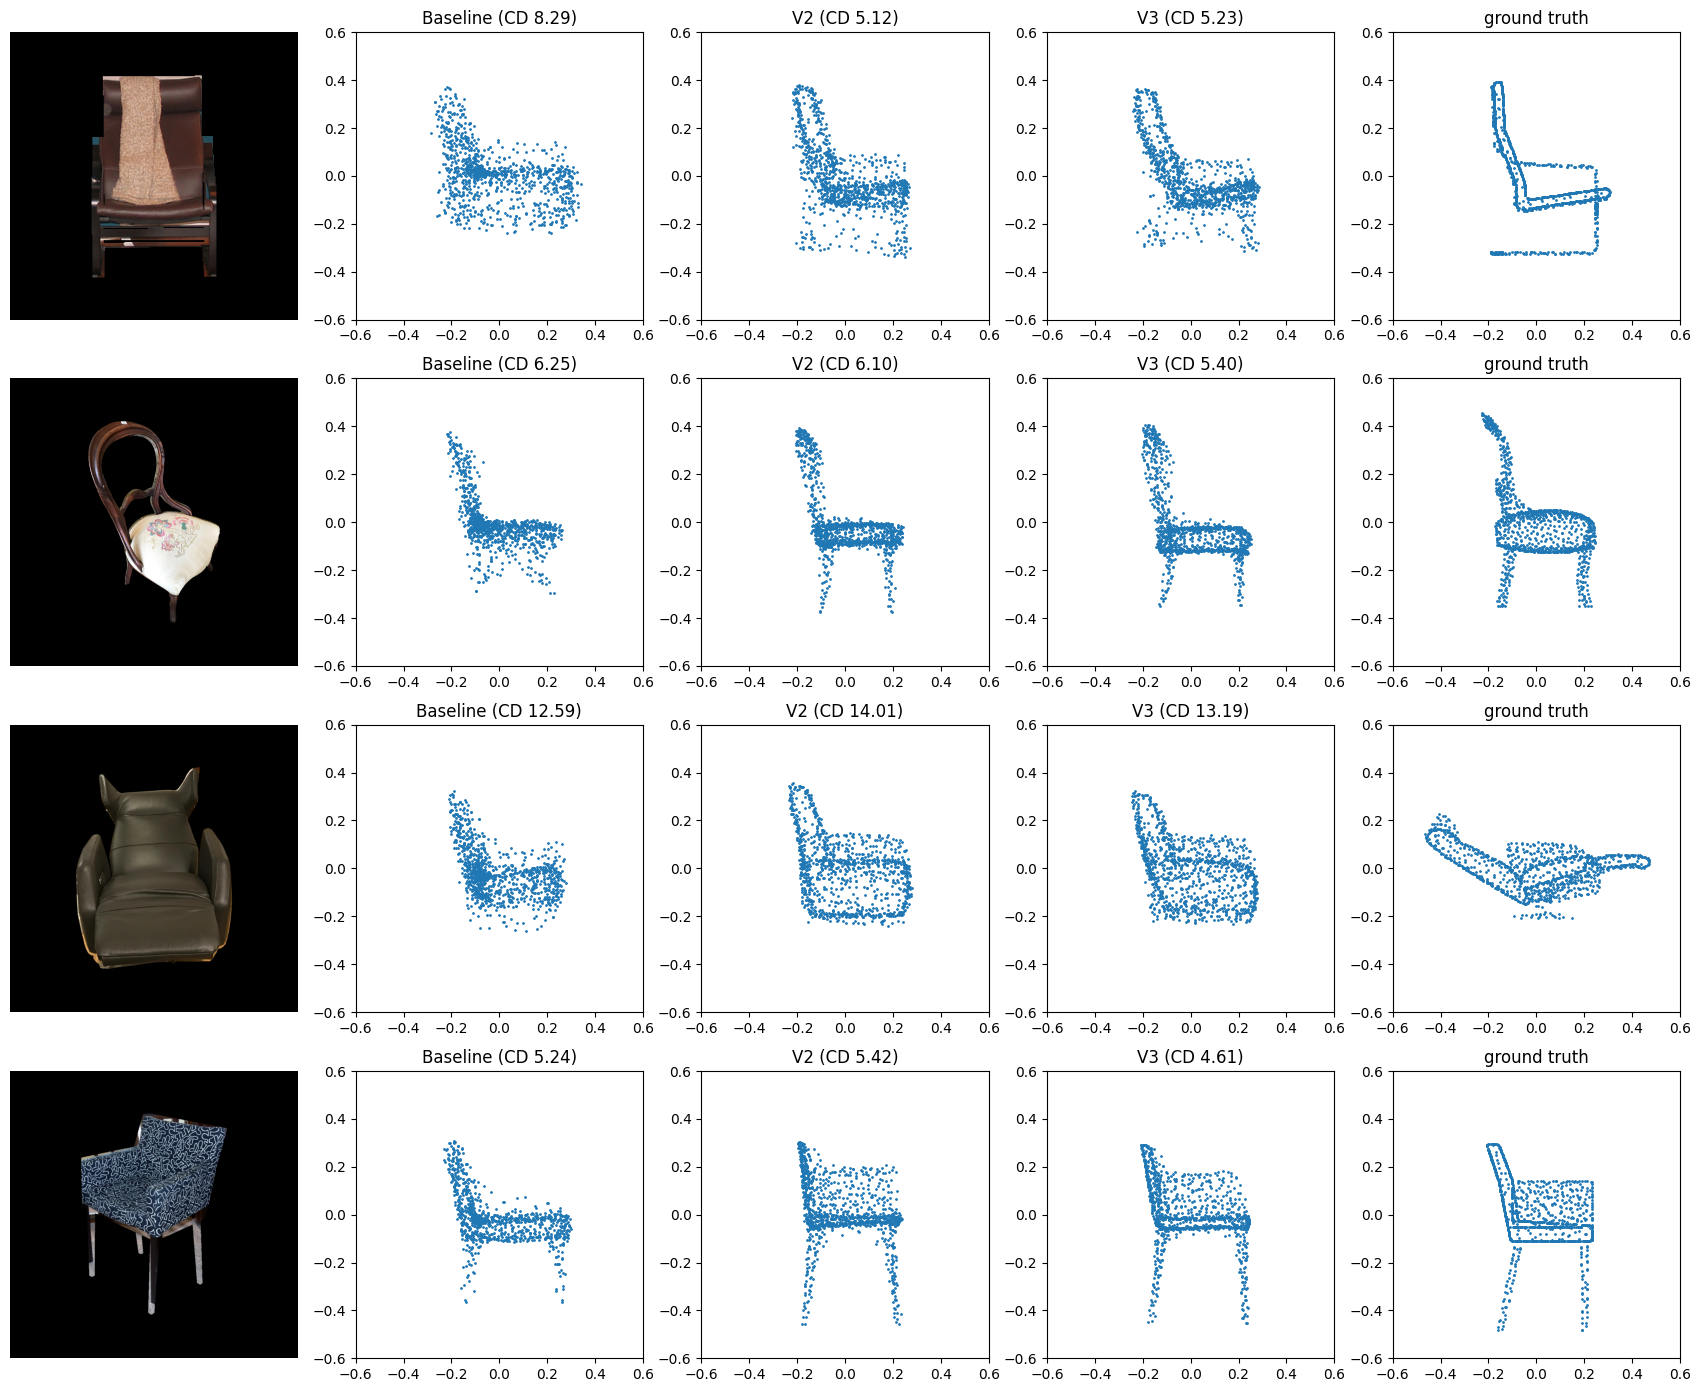

In [45]:
items = json.load(open("data/raw/pix3d/pix3d.json"))
items = [it for it in items if it["category"] == "chair" and not it["truncated"] and not it["occluded"]]
gt_file = lambda it: f"data/raw/pix3d_pointclouds/model/chair/{it['model'].split('/')[2]}/pcl_1024.npy"
items = [it for it in items if os.path.exists(gt_file(it))]
chosen = items[::700]

shapenet_chairs = load_points(cfg["data"], read_split("data/ShapeNet.json", ["chair"], "train")[:300]).cuda()
gt_files = sorted({gt_file(it) for it in items})
pix3d_chairs = torch.tensor(np.stack([np.load(f) for f in gt_files[:50]])).float().cuda()
rotation = choose_rotation(pix3d_chairs - pix3d_chairs.mean(1, keepdim=True), shapenet_chairs).numpy()

configs = {"Baseline": "configs/rgb2point.yaml", "V2": "configs/v2_dinov2.yaml", "V3": "configs/v3_finetune.yaml"}
models = {label: load_model(load_config(path), load_config(path)["output_dir"] + "/best.pt", "cuda") for label, path in configs.items()}

fig, ax = plt.subplots(len(chosen), 5, figsize=(17, 3.5 * len(chosen)))
for row, it in enumerate(chosen):
    image = load_image("data/raw/pix3d", it, (0, 0, 0))
    gt_points = np.load(gt_file(it))
    gt_points = (gt_points - gt_points.mean(0)) @ rotation.T
    ax[row, 0].imshow(image)
    ax[row, 0].axis("off")
    columns = [(label, predict(image, model, "cuda")) for label, model in models.items()] + [("ground truth", gt_points)]
    for col, (title, points) in enumerate(columns):
        a = ax[row, col + 1]
        a.scatter(points[:, 2], -points[:, 0], s=1)
        a.set_xlim(-0.6, 0.6)
        a.set_ylim(-0.6, 0.6)
        a.set_aspect("equal")
        if title != "ground truth":
            cd, _ = chamfer_fscore(torch.tensor(points)[None], torch.tensor(gt_points).float()[None])
            title = f"{title} (CD {cd.item() * 100:.2f})"
        a.set_title(title)
plt.tight_layout()
plt.show()

In [46]:
versions = {"Baseline": "base_rgb2point", "V0 no attention": "v0_no_attention", "V1 query decoder": "v1_query",
            "V2 DINOv2": "v2_dinov2", "V3 fine-tune + aug": "v3_finetune"}
rows = []
for test_set in ["test_full", "test_clean"]:
    for label, folder in versions.items():
        r = json.load(open(f"outputs/baseline1/{folder}/{test_set}.json"))
        row = [test_set, label]
        for class_id in list(CLASS_NAMES) + ["mean"]:
            row += [r[class_id]["cd"] * 100, r[class_id]["emd"] * 100, r[class_id]["fscore"]]
        row += [r["params_trainable"] / 1e6, r["time_ms"]]
        if os.path.exists(f"outputs/baseline1/{folder}/pix3d.json"):
            p = json.load(open(f"outputs/baseline1/{folder}/pix3d.json"))["chair"]
            row += [p["cd"] * 100, p["fscore"]]
        else:
            row += [None, None]
        rows.append(row)
columns = ["test set", "model"]
for name in list(CLASS_NAMES.values()) + ["mean"]:
    columns += [f"{name} CD", f"{name} EMD", f"{name} F"]
columns += ["trainable M", "ms/image", "Pix3D chair CD", "Pix3D chair F"]
pd.DataFrame(rows, columns=columns).round(3).T

,0,1,2,3,4,5,6,7,8,9
test set,test_full,test_full,test_full,test_full,test_full,test_clean,test_clean,test_clean,test_clean,test_clean
model,Baseline,V0 no attention,V1 query decoder,V2 DINOv2,V3 fine-tune + aug,Baseline,V0 no attention,V1 query decoder,V2 DINOv2,V3 fine-tune + aug
airplane CD,2.588,2.608,2.495,2.282,2.262,2.667,2.679,2.62,2.404,2.393
airplane EMD,4.687,4.052,4.225,3.391,3.324,4.489,3.948,4.124,3.421,3.365
airplane F,0.506,0.507,0.526,0.581,0.575,0.49,0.492,0.507,0.557,0.549
car CD,4.003,4.028,3.856,3.694,3.651,4.073,4.096,3.932,3.756,3.716
car EMD,3.37,3.375,3.204,3.062,3.063,3.449,3.447,3.293,3.145,3.15
car F,0.101,0.1,0.11,0.122,0.126,0.097,0.097,0.106,0.117,0.121
chair CD,5.363,5.412,4.906,4.424,4.36,5.506,5.612,5.071,4.586,4.539
chair EMD,7.903,6.355,5.926,5.477,5.266,7.755,6.333,5.917,5.492,5.331
